# Tahap 6: expanding-window preprocessing Way Urang

Validasi pengembangan pada train+validasi lama; **test akhir tidak dimuat atau dievaluasi**. Semua hasil sebelumnya dipertahankan. Empat fold kalender disimpan sebelum model. Konfigurasi tetap tahap 5B tanpa Curah Hujan.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from backtesting_stage6 import Backtest
from IPython.display import display, Markdown, Image
import pandas as pd
b=Backtest().prepare()
display(pd.DataFrame(b.plan))
display(pd.DataFrame(b.distributions))
display(pd.DataFrame(b.invariants))
print('Konfigurasi pra-model SHA256:',b.config_hash)


Fold kalender dikunci sebelum fitting: [{'Fold': 'Fold_01', 'Train mulai': Timestamp('2025-01-01 00:00:00'), 'Train akhir': Timestamp('2025-04-30 23:30:00'), 'Validasi mulai': Timestamp('2025-05-01 00:00:00'), 'Validasi akhir': Timestamp('2025-08-12 13:30:00'), 'Validasi akhir eksklusif': Timestamp('2025-08-12 14:00:00'), 'Slot train': 5760, 'Slot validasi': 4972, 'Durasi validasi jam': 2486.0, 'Index awal validasi': 5760, 'Index akhir validasi eksklusif': 10732}, {'Fold': 'Fold_02', 'Train mulai': Timestamp('2025-01-01 00:00:00'), 'Train akhir': Timestamp('2025-08-12 13:30:00'), 'Validasi mulai': Timestamp('2025-08-12 14:00:00'), 'Validasi akhir': Timestamp('2025-11-24 03:00:00'), 'Validasi akhir eksklusif': Timestamp('2025-11-24 03:30:00'), 'Slot train': 10732, 'Slot validasi': 4971, 'Durasi validasi jam': 2485.5, 'Index awal validasi': 10732, 'Index akhir validasi eksklusif': 15703}, {'Fold': 'Fold_03', 'Train mulai': Timestamp('2025-01-01 00:00:00'), 'Train akhir': Timestamp('2025-

,Fold,Train mulai,Train akhir,Validasi mulai,Validasi akhir,Validasi akhir eksklusif,Slot train,Slot validasi,Durasi validasi jam,Index awal validasi,Index akhir validasi eksklusif
0,Fold_01,2025-01-01,2025-04-30 23:30:00,2025-05-01 00:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,5760,4972,2486.0,5760,10732
1,Fold_02,2025-01-01,2025-08-12 13:30:00,2025-08-12 14:00:00,2025-11-24 03:00:00,2025-11-24 03:30:00,10732,4971,2485.5,10732,15703
2,Fold_03,2025-01-01,2025-11-24 03:00:00,2025-11-24 03:30:00,2026-03-07 16:30:00,2026-03-07 17:00:00,15703,4971,2485.5,15703,20674
3,Fold_04,2025-01-01,2026-03-07 16:30:00,2026-03-07 17:00:00,2026-06-19 06:00:00,2026-06-19 06:30:00,20674,4971,2485.5,20674,25645


,Fold,Bagian,Jumlah slot atau sampel,Target asli teramati,Minimum SO2,P25 SO2,Median SO2,P75 SO2,Maksimum SO2,Mean SO2,SD SO2,Target lebih 2.14
0,Fold_01,train,5760,3924,0.92,1.71,45.12,45.75,80.71,34.852548,21.836277,2833
1,Fold_01,validation,4972,4890,1.07,1.56,43.85,45.38,47.81,23.580558,21.929684,2456
2,Fold_02,train,10732,8814,0.92,1.58,44.82,45.58,80.71,28.598857,22.592547,5289
3,Fold_02,validation,4971,4969,1.04,1.48,1.56,1.64,2.14,1.560920,0.131798,0
4,Fold_03,train,15703,13783,0.92,1.52,1.66,45.17,80.71,18.851233,22.247512,5289
5,Fold_03,validation,4971,4969,1.08,1.49,1.56,1.63,2.04,1.562727,0.128728,0
6,Fold_04,train,20674,18752,0.92,1.51,1.61,44.65,80.71,14.270037,20.542934,5289
7,Fold_04,validation,4971,4969,1.09,1.49,1.56,1.63,2.06,1.560231,0.105295,0


,Parameter,Sama dengan5B,Nilai
0,covariates,True,"['PM10', 'PM2.5', 'CO', 'O3', 'NO2', 'Kec.Angi..."
1,horizon_slots,True,1
2,horizon_minutes,True,30
3,so2_lags,True,"[0, 1, 2, 6, 12, 24, 48]"
4,covariate_lag_slots,True,1
5,ffill_limit_slots,True,4
6,knn,True,"{'k': 10, 'weights': 'distance', 'metric': 'na..."
7,ridge,True,"{'alpha': 1.0, 'fit_intercept': True, 'solver'..."
8,warmup_slots,True,4320
9,prefix_update_slots,True,1440


## Pemeriksaan kecukupan sebelum Ridge

Kalibrasi 90 hari, buffer 48 slot, minimal 340 target train bersama dan dua nilai berbeda. Seluruh fold diperiksa sebelum satu pun Ridge dilatih. Distribusi target dan kehilangan karena irisan diperiksa tanpa mengubah kalender berdasarkan skor.

In [2]:
b.preprocess_and_check_all()
display(pd.DataFrame([f.gate for f in b.folds]))
display(pd.DataFrame([r for f in b.folds for r in f.flow]))
display(pd.DataFrame([r for f in b.folds for r in f.lost]))
display(pd.DataFrame([f.train_distribution[0] for f in b.folds]))
print('Jumlah Ridge sebelum seluruh gate:',b.fit_count)


Histori kausal: 2025-04-01 00:00:00 - 2025-04-30 23:30:00
Histori kausal: 2025-05-01 00:00:00 - 2025-08-12 13:00:00
Gate Fold_01 {'Fold': 'Fold_01', 'Ridge fit count global sebelum gate': 0, 'Jumlah fitur': 34, 'Minimum train bersama disyaratkan': 340, 'Jumlah train bersama': 1379, 'Target unik train bersama': 284, 'Cukup sampel': True, 'Kalibrasi mulai': Timestamp('2025-01-01 00:00:00'), 'Kalibrasi sampai': Timestamp('2025-03-31 23:30:00'), 'Origin dipurge': Timestamp('2025-04-30 23:30:00'), 'Target origin dipurge': Timestamp('2025-05-01 00:00:00')}
Histori kausal: 2025-04-01 00:00:00 - 2025-04-30 23:30:00
Histori kausal: 2025-05-01 00:00:00 - 2025-05-30 23:30:00
Histori kausal: 2025-05-31 00:00:00 - 2025-06-29 23:30:00
Histori kausal: 2025-06-30 00:00:00 - 2025-07-29 23:30:00
Histori kausal: 2025-07-30 00:00:00 - 2025-08-12 13:30:00
Histori kausal: 2025-08-12 14:00:00 - 2025-11-24 02:30:00
Gate Fold_02 {'Fold': 'Fold_02', 'Ridge fit count global sebelum gate': 0, 'Jumlah fitur': 34, 

,Fold,Ridge fit count global sebelum gate,Jumlah fitur,Minimum train bersama disyaratkan,Jumlah train bersama,Target unik train bersama,Cukup sampel,Kalibrasi mulai,Kalibrasi sampai,Origin dipurge,Target origin dipurge
0,Fold_01,0,34,340,1379,284,True,2025-01-01,2025-03-31 23:30:00,2025-04-30 23:30:00,2025-05-01 00:00:00
1,Fold_02,0,34,340,6190,436,True,2025-01-01,2025-03-31 23:30:00,2025-08-12 13:30:00,2025-08-12 14:00:00
2,Fold_03,0,34,340,11154,449,True,2025-01-01,2025-03-31 23:30:00,2025-11-24 03:00:00,2025-11-24 03:30:00
3,Fold_04,0,34,340,16086,449,True,2025-01-01,2025-03-31 23:30:00,2026-03-07 16:30:00,2026-03-07 17:00:00


,Fold,Pipeline,Seluruh origin train,Setelah kalibrasi buffer purge,Target train asli,Setelah fitur finite mandiri,Final train bersama
0,Fold_01,P0_median,5760,1391,1385,1385,1379
1,Fold_01,P1_ffill_L4,5760,1391,1385,1385,1379
2,Fold_01,P2_knn_k10,5760,1391,1385,1379,1379
3,Fold_02,P0_median,10732,6363,6275,6275,6190
4,Fold_02,P1_ffill_L4,10732,6363,6275,6214,6190
5,Fold_02,P2_knn_k10,10732,6363,6275,6202,6190
6,Fold_03,P0_median,15703,11334,11244,11244,11154
7,Fold_03,P1_ffill_L4,15703,11334,11244,11180,11154
8,Fold_03,P2_knn_k10,15703,11334,11244,11169,11154
9,Fold_04,P0_median,20674,16305,16213,16213,16086


,Fold,Pipeline,Layak mandiri,Aktual bersama,Keluar karena irisan,Jumlah slot atau sampel,Target asli teramati,Minimum SO2,P25 SO2,Median SO2,P75 SO2,Maksimum SO2,Mean SO2,SD SO2,Target lebih 2.14
0,Fold_01,P0_median,1385,1379,6,6,6,44.55,44.7225,45.200,45.7750,46.28,45.293333,0.697357,6
1,Fold_01,P1_ffill_L4,1385,1379,6,6,6,44.55,44.7225,45.200,45.7750,46.28,45.293333,0.697357,6
2,Fold_01,P2_knn_k10,1379,1379,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,Fold_02,P0_median,6275,6190,85,85,85,1.16,1.6900,44.870,45.4800,46.68,29.877765,21.014197,55
4,Fold_02,P1_ffill_L4,6214,6190,24,24,24,1.28,1.5450,1.625,12.5850,46.28,12.511667,19.336794,6
5,Fold_02,P2_knn_k10,6202,6190,12,12,12,1.16,1.6900,1.690,1.6900,1.69,1.625000,0.163123,0
6,Fold_03,P0_median,11244,11154,90,90,90,1.16,1.6900,44.680,45.4300,46.68,28.303667,21.433240,55
7,Fold_03,P1_ffill_L4,11180,11154,26,26,26,1.28,1.5350,1.600,1.8925,46.28,11.667692,18.785318,6
8,Fold_03,P2_knn_k10,11169,11154,15,15,15,1.16,1.5950,1.690,1.6900,1.70,1.609333,0.156865,0
9,Fold_04,P0_median,16213,16086,127,127,127,1.16,1.5650,1.730,45.1950,46.68,20.514094,21.754448,55


,Fold,Bulan target,Jumlah slot atau sampel,Target asli teramati,Minimum SO2,P25 SO2,Median SO2,P75 SO2,Maksimum SO2,Mean SO2,SD SO2,Target lebih 2.14
0,Fold_01,seluruh train bersama,1379,1379,43.53,45.00,45.40,45.815,47.43,45.404467,0.624020,1379
1,Fold_02,seluruh train bersama,6190,6190,1.07,1.60,44.85,45.540,47.81,28.377034,21.377898,3786
2,Fold_03,seluruh train bersama,11154,11154,1.04,1.53,1.64,45.010,47.81,16.442741,20.766151,3786
3,Fold_04,seluruh train bersama,16086,16086,1.04,1.51,1.61,1.860,47.81,11.880490,18.603447,3786


## Fit dari nol per fold dan evaluasi OOF

Parameter imputasi hanya prefix train; validasi dibekukan. Fitur historis dibentuk kausal sebelum lag. Train bersama, target asli, purge pada batas. Persistence memakai pengamatan asli terakhir pada/sebelum origin. Semua metrik bersama memakai timestamp identik.

Ridge selesai: Fold_01
Ridge selesai: Fold_02
Ridge selesai: Fold_03
Ridge selesai: Fold_04


,Fold,Pipeline,Domain,Jumlah prediksi,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Jumlah absolute error,Jumlah squared error,Jumlah signed error,Prediksi negatif,SHA256 timestamp target
0,Fold_01,P0_median,seluruh berhasil,4890,4890,100.000000,16.458916,24.448670,15.883840,80484.097456,2.922936e+06,77671.978109,108,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,P0_median,irisan semua metode,4811,4890,98.384458,16.491830,24.456627,15.916489,79342.192178,2.877587e+06,76574.226968,106,5e0f4af08ba7ae2f5c7bd9a586bff1337c569070567ce2...
2,Fold_01,P1_ffill_L4,seluruh berhasil,4829,4890,98.752556,16.656634,24.648912,16.110573,80434.887429,2.933950e+06,77797.954952,104,9ecd5b2c285277ca02ab07a6389cf03b863c260c901479...
3,Fold_01,P1_ffill_L4,irisan semua metode,4811,4890,98.384458,16.599086,24.601243,16.058483,79858.201513,2.911719e+06,77257.359360,101,5e0f4af08ba7ae2f5c7bd9a586bff1337c569070567ce2...
4,Fold_01,P2_knn_k10,seluruh berhasil,4823,4890,98.629857,16.543760,24.496439,15.972954,79790.552536,2.894164e+06,77037.557948,106,ef5500fd1ed9f75bfab2f4320f349c3ff936858c8572fe...
5,Fold_01,P2_knn_k10,irisan semua metode,4811,4890,98.384458,16.479999,24.436651,15.907770,79285.276448,2.872888e+06,76532.281860,106,5e0f4af08ba7ae2f5c7bd9a586bff1337c569070567ce2...
6,Fold_01,Persistence,seluruh berhasil,4890,4890,100.000000,0.430562,0.885256,0.009049,2105.450000,3.832185e+03,44.250000,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
7,Fold_01,Persistence,irisan semua metode,4811,4890,98.384458,0.429472,0.887766,0.009588,2066.190000,3.791690e+03,46.130000,0,5e0f4af08ba7ae2f5c7bd9a586bff1337c569070567ce2...
8,Fold_02,P0_median,seluruh berhasil,4969,4969,100.000000,0.151868,0.513461,-0.018822,754.633493,1.310038e+03,-93.527579,0,1d688ac4f4a18f27cc83901b88374c4d81006e9beb785d...
9,Fold_02,P0_median,irisan semua metode,4964,4969,99.899376,0.143361,0.288234,-0.027250,711.645229,4.124028e+02,-135.267229,0,cf9a5bca4b94191bd12ef70a23faf8752d3d9c15d971db...


,Fold,Pipeline,Domain,Jumlah prediksi,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Jumlah absolute error,Jumlah squared error,Jumlah signed error,Prediksi negatif,SHA256 timestamp target
0,Gabungan_OOF,P0_median,seluruh berhasil,19797,19797,100.000000,4.159122,12.154344,3.917585,82338.139961,2.924573e+06,77556.437432,114,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
1,Gabungan_OOF,P0_median,irisan semua metode,19638,19797,99.196848,4.131825,12.106569,3.891067,81140.785636,2.878322e+06,76412.764209,112,f80a59f07478810e8e5b2521614b280f9b75cd7a9cf4a2...
2,Gabungan_OOF,P1_ffill_L4,seluruh berhasil,19662,19797,99.318078,4.178106,12.216234,3.958260,82149.915030,2.934285e+06,77827.306409,104,c114904a0d9542bf0970e473c2642b042d2f9c9683807b...
3,Gabungan_OOF,P1_ffill_L4,irisan semua metode,19638,19797,99.196848,4.153809,12.177303,3.935557,81572.507983,2.912054e+06,77286.462398,101,f80a59f07478810e8e5b2521614b280f9b75cd7a9cf4a2...
4,Gabungan_OOF,P2_knn_k10,seluruh berhasil,19724,19797,99.631257,4.132652,12.114048,3.907560,81512.420856,2.894500e+06,77072.713379,106,3c5c2031fc43a7726d70f48ec9ae794773db1bf783d827...
5,Gabungan_OOF,P2_knn_k10,irisan semua metode,19638,19797,99.196848,4.124500,12.095837,3.898860,80996.922970,2.873221e+06,76565.819727,106,f80a59f07478810e8e5b2521614b280f9b75cd7a9cf4a2...
6,Gabungan_OOF,Persistence,seluruh berhasil,19797,19797,100.000000,0.206335,0.464340,0.002240,4084.810000,4.268464e+03,44.350000,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
7,Gabungan_OOF,Persistence,irisan semua metode,19638,19797,99.196848,0.205474,0.463880,0.002356,4035.090000,4.225795e+03,46.270000,0,f80a59f07478810e8e5b2521614b280f9b75cd7a9cf4a2...


,Pipeline,Domain,Jumlah fold,MAE rata-rata fold,MAE SD fold,MAE minimum,MAE maksimum,RMSE rata-rata fold,RMSE SD fold,RMSE minimum,RMSE maksimum,Bias rata-rata fold,Bias SD fold,Bias minimum,Bias maksimum,Cakupan persen rata-rata fold,Cakupan persen SD fold,Cakupan persen minimum,Cakupan persen maksimum,Jumlah prediksi rata-rata fold,Jumlah prediksi SD fold,Jumlah prediksi minimum,Jumlah prediksi maksimum
0,P0_median,seluruh berhasil,4,4.208009,8.167297,0.101526,16.458916,6.330811,12.079600,0.163840,24.448670,3.965147,7.945801,-0.018822,15.883840,100.000000,0.000000,100.000000,100.000000,4949.25,39.500000,4890.0,4969.0
1,P0_median,irisan semua metode,4,4.213900,8.185305,0.101352,16.491830,6.276281,12.120345,0.163822,24.456627,3.970982,7.963681,-0.027250,15.916489,99.193619,0.621392,98.384458,99.899376,4909.50,67.431447,4811.0,4964.0
2,P1_ffill_L4,seluruh berhasil,4,4.250855,8.270528,0.099915,16.656634,6.274372,12.249703,0.128604,24.648912,4.029116,8.054306,-0.003029,16.110573,99.315831,0.485947,98.752556,99.939626,4915.50,59.668529,4829.0,4966.0
3,P1_ffill_L4,irisan semua metode,4,4.236467,8.241754,0.099893,16.599086,6.262456,12.225869,0.128587,24.601243,4.016082,8.028269,-0.003029,16.058483,99.193619,0.621392,98.384458,99.899376,4909.50,67.431447,4811.0,4964.0
4,P2_knn_k10,seluruh berhasil,4,4.222605,8.214111,0.100020,16.543760,6.236107,12.173564,0.128809,24.496439,3.995008,7.985299,-0.002578,15.972954,99.627277,0.664947,98.629857,99.959750,4931.00,72.000000,4823.0,4967.0
5,P2_knn_k10,irisan semua metode,4,4.206561,8.182300,0.099866,16.479999,6.221012,12.143768,0.128568,24.436651,3.978627,7.952764,-0.002855,15.907770,99.193619,0.621392,98.384458,99.899376,4909.50,67.431447,4811.0,4964.0
6,Persistence,seluruh berhasil,4,0.207226,0.149373,0.115935,0.430562,0.349112,0.357753,0.149092,0.885256,0.002267,0.004521,-0.000020,0.009049,100.000000,0.000000,100.000000,100.000000,4949.25,39.500000,4890.0,4969.0
7,Persistence,irisan semua metode,4,0.206944,0.148842,0.115818,0.429472,0.349736,0.359013,0.148959,0.887766,0.002404,0.004792,-0.000166,0.009588,99.193619,0.621392,98.384458,99.899376,4909.50,67.431447,4811.0,4964.0


,Fold,Pipeline,Peringkat MAE,Peringkat RMSE,MAE,RMSE
0,Fold_01,P0_median,2.0,2.0,16.491830,24.456627
1,Fold_01,P1_ffill_L4,3.0,3.0,16.599086,24.601243
2,Fold_01,P2_knn_k10,1.0,1.0,16.479999,24.436651
3,Fold_02,P0_median,3.0,3.0,0.143361,0.288234
4,Fold_02,P1_ffill_L4,2.0,2.0,0.127656,0.166156
5,Fold_02,P2_knn_k10,1.0,1.0,0.127065,0.164926
6,Fold_03,P0_median,1.0,3.0,0.119055,0.196441
7,Fold_03,P1_ffill_L4,2.0,1.0,0.119231,0.153836
8,Fold_03,P2_knn_k10,3.0,2.0,0.119314,0.153905
9,Fold_04,P0_median,3.0,3.0,0.101352,0.163822


,Fold,Pipeline,Jumlah timestamp sama,Delta MAE vs persistence,Delta RMSE vs persistence,Delta bias vs persistence,Perbaikan MAE persen,Perbaikan RMSE persen
0,Fold_01,P0_median,4811,16.062358,23.568860,15.906900,-3740.024014,-2654.849130
1,Fold_01,P1_ffill_L4,4811,16.169614,23.713477,16.048894,-3764.997968,-2671.139063
2,Fold_01,P2_knn_k10,4811,16.050527,23.548884,15.898182,-3737.269392,-2652.598946
3,Fold_02,P0_median,4964,0.000386,0.104526,-0.027256,-0.269853,-56.897562
4,Fold_02,P1_ffill_L4,4964,-0.015319,-0.017552,0.008753,10.714546,9.554215
5,Fold_02,P2_knn_k10,4964,-0.015911,-0.018782,0.009498,11.128371,10.223790
6,Fold_03,P0_median,4932,-0.020456,0.017930,-0.009057,14.662544,-10.044224
7,Fold_03,P1_ffill_L4,4932,-0.020281,-0.024675,-0.003217,14.536849,13.822813
8,Fold_03,P2_knn_k10,4932,-0.020197,-0.024606,-0.003044,14.477049,13.784178
9,Fold_04,P0_median,4931,-0.014466,0.014863,0.003724,12.490493,-9.978110


,Fold,Pembentukan histori semua pipeline detik,Jumlah prefix refit,Fit imputer median scaler KNN detik,Transform KNN detik
0,Fold_01,0.271963,2,0.030529,0.026163
1,Fold_02,1.024618,6,0.048865,0.810194
2,Fold_03,2.654292,9,0.095599,2.344183
3,Fold_04,6.590626,13,0.267075,5.995754


,Fold,Pipeline,Jumlah train,Scaler fitur fit detik,Ridge fit detik,Predict detik
0,Fold_01,P0_median,1379,0.001493,0.003114,0.002313
1,Fold_01,P1_ffill_L4,1379,0.001675,0.003886,0.002680
2,Fold_01,P2_knn_k10,1379,0.002430,0.006268,0.003291
3,Fold_02,P0_median,6190,0.011041,0.019928,0.004597
4,Fold_02,P1_ffill_L4,6190,0.014609,0.025017,0.004330
5,Fold_02,P2_knn_k10,6190,0.011453,0.019500,0.003509
6,Fold_03,P0_median,11154,0.025442,0.040021,0.004550
7,Fold_03,P1_ffill_L4,11154,0.025762,0.040466,0.005399
8,Fold_03,P2_knn_k10,11154,0.020657,0.029900,0.006866
9,Fold_04,P0_median,16086,0.021280,0.050143,0.004079


,File,SHA256 sebelum,SHA256 sesudah,Identik
0,outputs\audit_kualitas_data.xlsx,7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093...,7e1a6059f5660aa50deec62ae7d498361fadafa0b4e093...,True
1,outputs\audit_kualitas_tables.json,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,True
2,outputs\audit_struktur_data.json,75de5795076e22bb46784e70b238b2778a7e77f75953e9...,75de5795076e22bb46784e70b238b2778a7e77f75953e9...,True
3,outputs\environment_freeze.txt,9137e9aad6f786fe6db4e0ef7fa7b8bbb6f2a400d17de6...,9137e9aad6f786fe6db4e0ef7fa7b8bbb6f2a400d17de6...,True
4,outputs\forecasting_acuan_way_urang.xlsx,1bfd0761f299d27faf7455448520ac11d8231feb7fc8d5...,1bfd0761f299d27faf7455448520ac11d8231feb7fc8d5...,True
...,...,...,...,...
90,notebooks\02_audit_kualitas_data.ipynb,031948f8d28d754b8fe0bf6a04e4341d01a7af32ff1054...,031948f8d28d754b8fe0bf6a04e4341d01a7af32ff1054...,True
91,notebooks\04_pilot_imputasi_way_urang.ipynb,5d505fd390bf47153b587fde96c2b7016fde07cc51593a...,5d505fd390bf47153b587fde96c2b7016fde07cc51593a...,True
92,notebooks\05B_ablasi_curah_hujan.ipynb,354eab7de278079910aaec21810dba4a71dbd3c0aee7f4...,354eab7de278079910aaec21810dba4a71dbd3c0aee7f4...,True
93,notebooks\05_forecasting_acuan_way_urang.ipynb,630eab31b3eada0aa7cb01bf889aba89062c3dfbb14c83...,630eab31b3eada0aa7cb01bf889aba89062c3dfbb14c83...,True


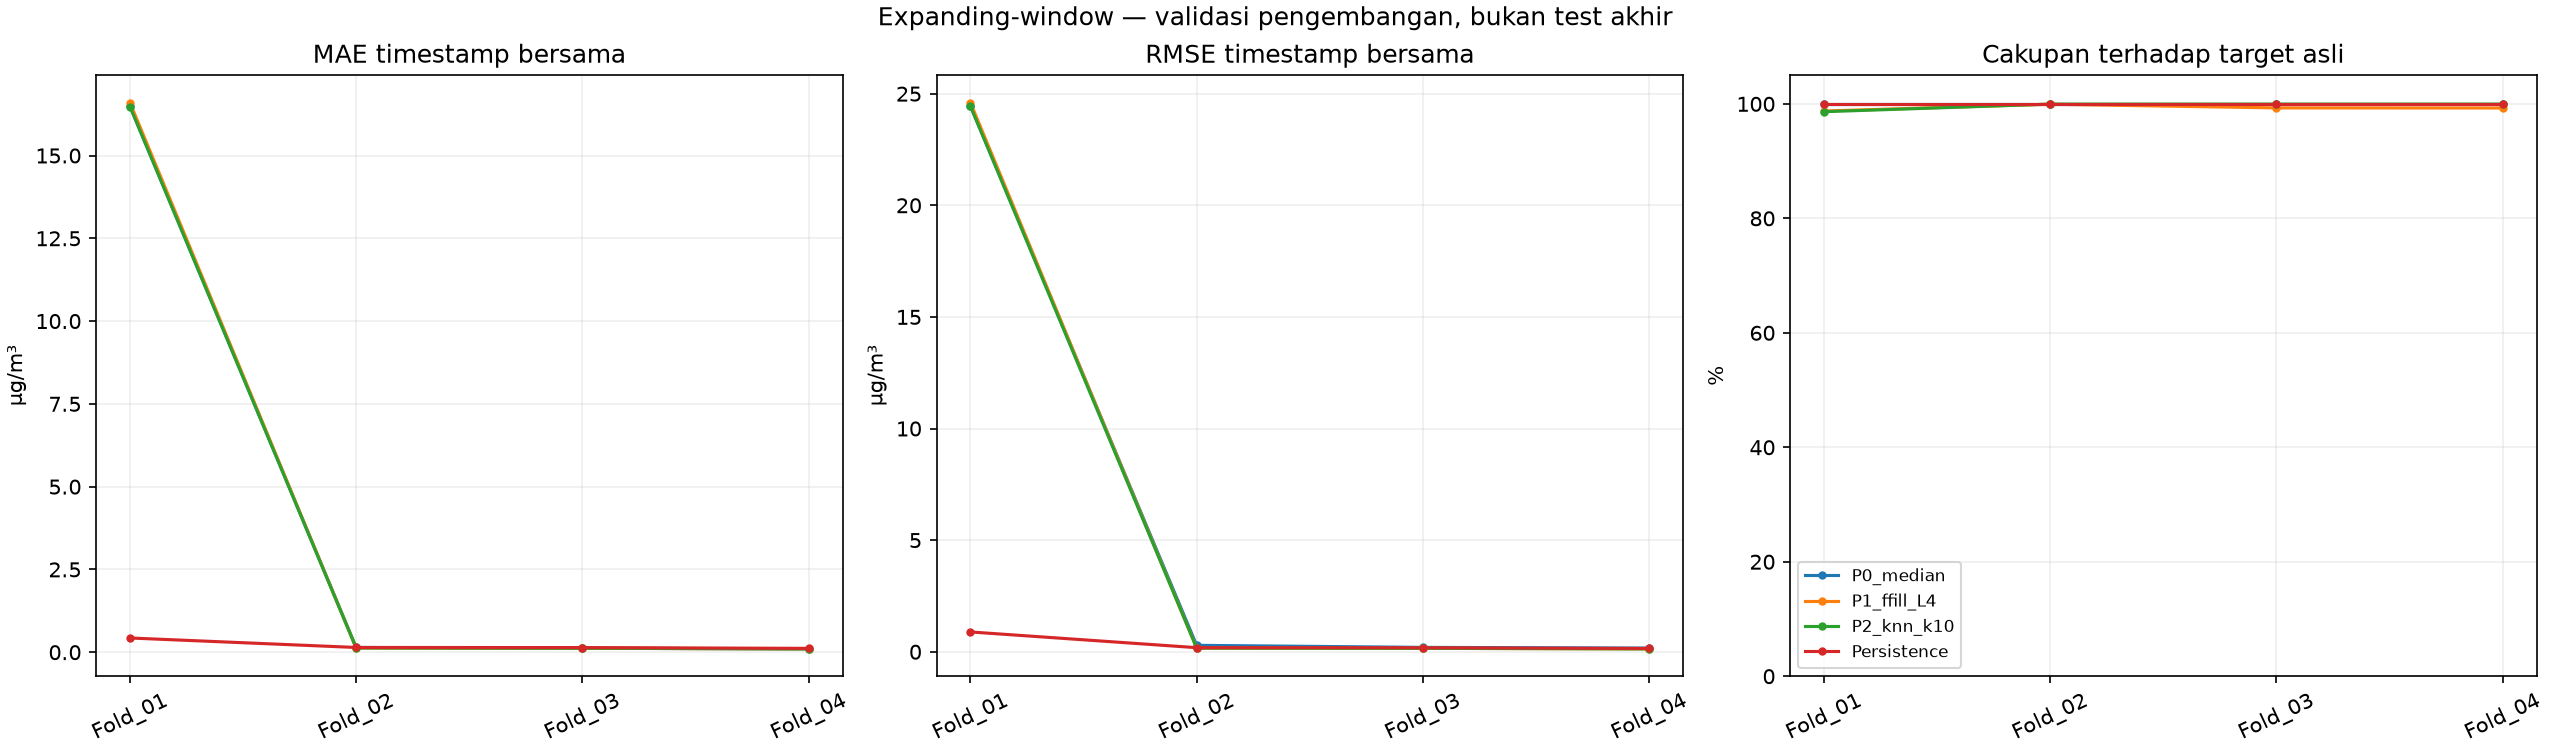

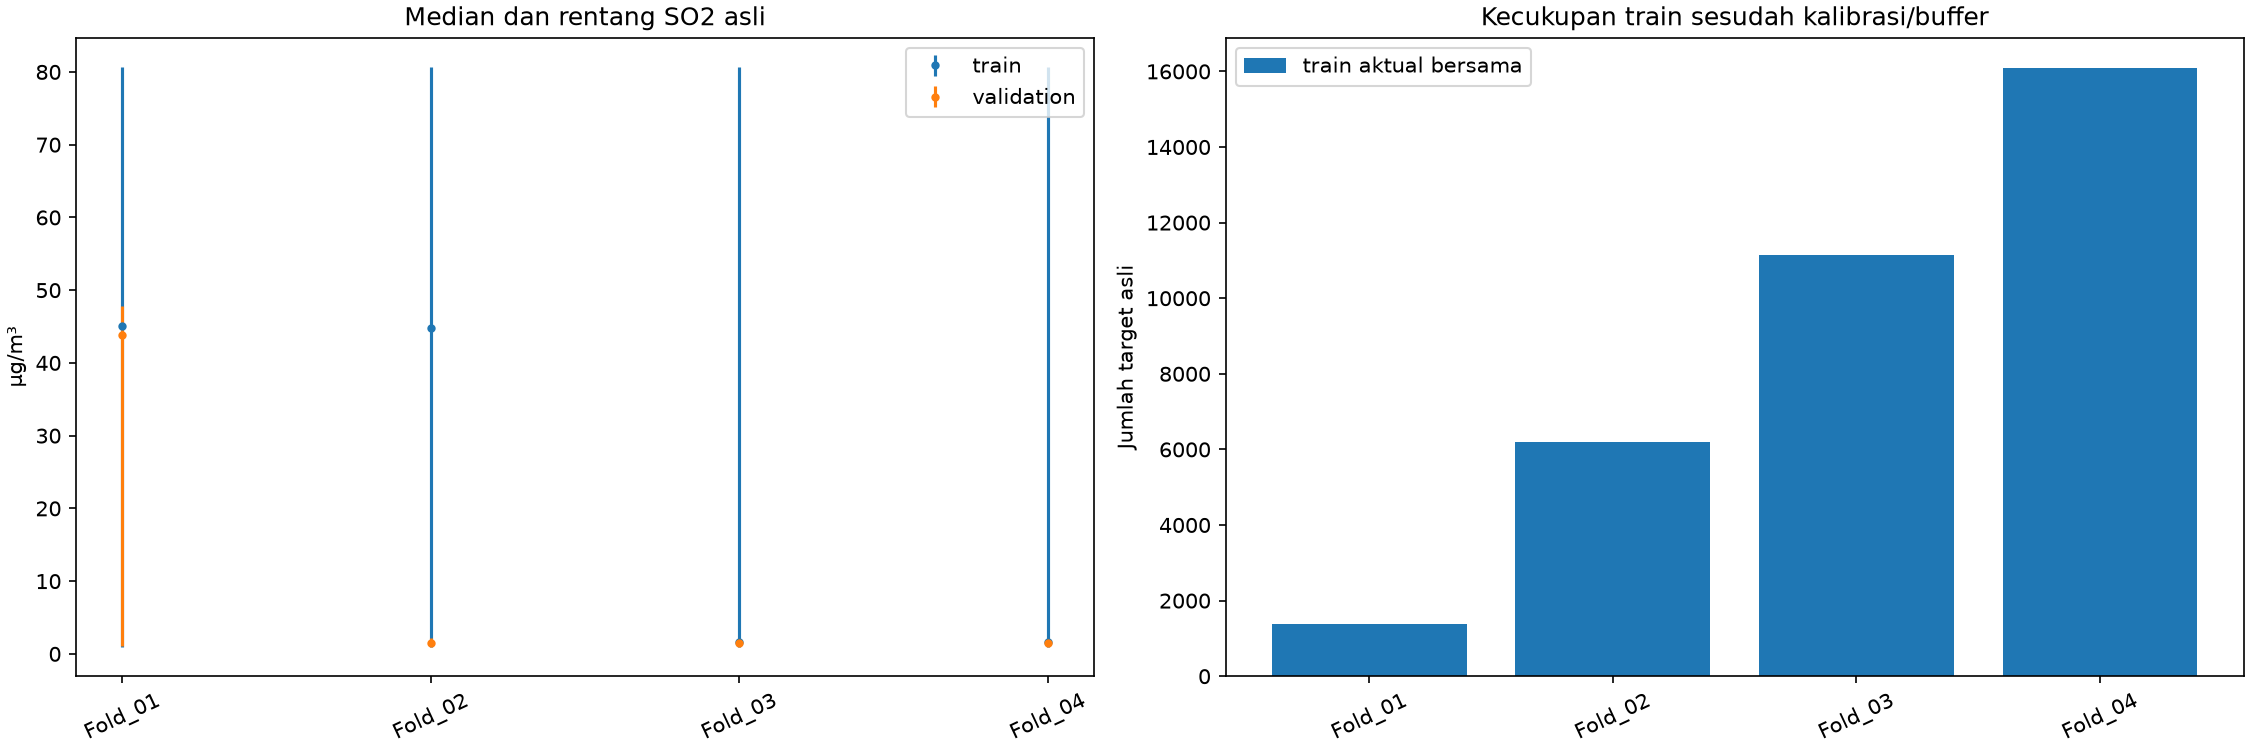

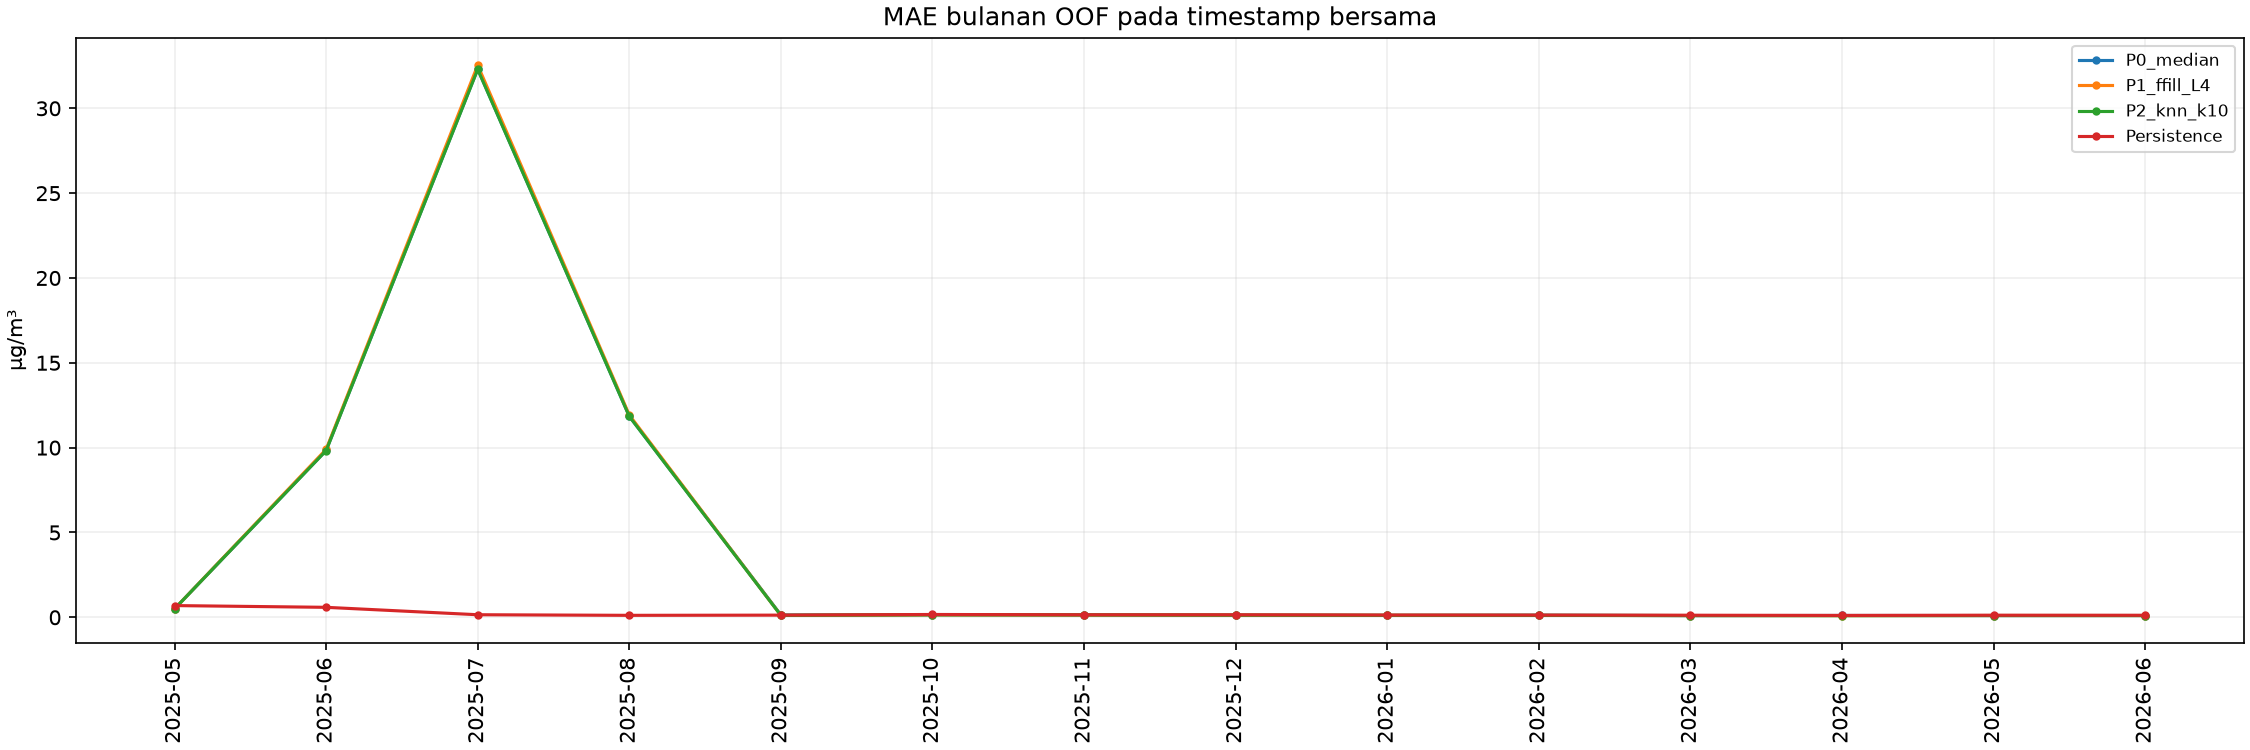

In [3]:
b.run_models()
display(pd.DataFrame(b.metrics))
display(pd.DataFrame(b.pooled))
display(pd.DataFrame(b.summary))
display(pd.DataFrame(b.ranks))
display(pd.DataFrame(b.deltas))
display(pd.DataFrame(b.preprocess_time))
display(pd.DataFrame(b.timing))
display(pd.DataFrame(b.integrity))
for name in ['metrik_dan_cakupan_fold.png','distribusi_dan_train_fold.png','mae_bulanan_oof.png']:
    display(Image(filename=str(ROOT/'outputs/figures/backtesting_way_urang'/name)))


In [4]:
b.export_excel()
display(Markdown((ROOT/'outputs/ringkasan_backtesting_preprocessing.md').read_text(encoding='utf-8')))


{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Fold","Pipeline","Domain","Jumlah prediksi","Denominator target asli","Cakupan persen"],["Gabungan_OOF","P0_median","seluruh berhasil",19797,19797,100],["Gabungan_OOF","P0_median","irisan semua metode",19638,19797,99.19684800727383],["Gabungan_OOF","P1_ffill_L4","seluruh berhasil",19662,19797,99.31807849674193]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\backtesting_preprocessing.xlsx.inspect.ndjson
Ekspor selesai: 25 sheet.



# Tahap 6 — expanding-window preprocessing Way Urang

Ini **validasi pengembangan**: development set adalah train dan validasi lama yang telah digunakan pada eksperimen sebelumnya. Test akhir mulai **2026-06-19 06:30** tetap dikunci; nilainya tidak dimuat atau dievaluasi. Way Urang masih pilot sementara.

## Rancangan yang dikunci sebelum model

Train awal 120 hari kalender; sisa development dibagi empat jendela validasi tidak tumpang tindih, berbeda paling banyak satu slot 30 menit. Konfigurasi tersimpan di `backtesting_way_urang/fold_config_locked.json`; SHA256 37d0fc2f8ef09b7a44f6b2f666f598160f78a9fe5f955ef19c3d8969497c13b5. Tidak ada penyesuaian berdasarkan skor.

| Fold | Train mulai | Train akhir | Validasi mulai | Validasi akhir | Slot train | Slot validasi |
|---|---|---|---|---|---|---|
| Fold_01 | 2025-01-01 00:00:00 | 2025-04-30 23:30:00 | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 5760 | 4972 |
| Fold_02 | 2025-01-01 00:00:00 | 2025-08-12 13:30:00 | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 10732 | 4971 |
| Fold_03 | 2025-01-01 00:00:00 | 2025-11-24 03:00:00 | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 15703 | 4971 |
| Fold_04 | 2025-01-01 00:00:00 | 2026-03-07 16:30:00 | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 20674 | 4971 |

Kalibrasi tetap 90 hari pertama train terkait, pembaruan prefix 30 hari dan buffer histori 48 slot. Kecukupan ditetapkan sebelum Ridge: minimal 340 sampel bersama (10 × 34 fitur) dan dua nilai target berbeda. Ini pemeriksaan kecukupan komputasional, bukan jaminan daya statistik. Seluruh gate diperiksa saat jumlah fit Ridge masih nol; seluruhnya lulus tanpa mengubah batas fold.

| Fold | Jumlah train bersama | Target unik train bersama | Cukup sampel | Ridge fit count global sebelum gate |
|---|---|---|---|---|
| Fold_01 | 1379 | 284 | True | 0 |
| Fold_02 | 6190 | 436 | True | 0 |
| Fold_03 | 11154 | 449 | True | 0 |
| Fold_04 | 16086 | 449 | True | 0 |

## Parameter dan kausalitas

Sama dengan 5B tanpa Curah Hujan: horizon satu slot/30 menit; SO₂ lag 0, 1, 2, 6, 12, 24, 48; sepuluh kovariat lag satu slot: PM10, PM2.5, CO, O3, NO2, Kec.Angin, Kelembaban, Suhu, Tek.Udara, Sol.Rad. Sebanyak 17 fitur numerik ditambah 17 indikator missing asli. Ridge alpha=1, intercept aktif, solver SVD; scaler fitur diestimasi hanya pada train bersama fold tersebut.

P0 mengisi dengan median prefix train; P1 memakai pengamatan asli sebelumnya maksimum empat slot, tanpa fallback; P2 KNN k=10, distance weighting, nan-euclidean, scaling prefix train, donor SO₂ asli dan minimal dua kovariat asli. Semua estimator dibuat ulang dari nol pada setiap fold. Kalibrasi dan prefix train hanya menggunakan waktu sebelumnya; parameter imputasi validasi dibekukan pada akhir train. Histori direkonstruksi sebelum pembentukan lag. Tidak ada nilai target masa depan, backward fill, interpolasi dua arah atau clipping. Pengamatan validasi fold terdahulu boleh menjadi data train fold berikut setelah waktunya tersedia.

Asumsi ketersediaan tetap: SO₂ pada origin sudah tersedia saat prediksi diterbitkan, kovariat sudah tersedia dengan keterlambatan satu slot. Ini belum dikonfirmasi penyedia data. Tidak ada waktu mentah atau arah angin linear sebagai fitur. Nol, lonjakan dan rentetan konstan dipertahankan; penanda missing asli ikut fitur. Off-grid Way Urang yang diaudit sebelumnya tidak memiliki SO₂; tidak dibulatkan.

Origin train terakhir yang targetnya memasuki validasi dipurge. Target selalu pengamatan SO₂ asli; target kosong tidak diisi. Persistence memakai SO₂ asli terakhir pada atau sebelum origin, termasuk donor lebih lama ketika origin kosong. Usia donor dalam slot disimpan untuk setiap prediksi.

## Distribusi dan seleksi sampel

| Fold | Bagian | Target asli teramati | Minimum SO2 | Median SO2 | Maksimum SO2 | Target lebih 2.14 |
|---|---|---|---|---|---|---|
| Fold_01 | train | 3924 | 0.92 | 45.12 | 80.71 | 2833 |
| Fold_01 | validation | 4890 | 1.07 | 43.85 | 47.81 | 2456 |
| Fold_02 | train | 8814 | 0.92 | 44.82 | 80.71 | 5289 |
| Fold_02 | validation | 4969 | 1.04 | 1.56 | 2.14 | 0 |
| Fold_03 | train | 13783 | 0.92 | 1.66 | 80.71 | 5289 |
| Fold_03 | validation | 4969 | 1.08 | 1.56 | 2.04 | 0 |
| Fold_04 | train | 18752 | 0.92 | 1.61 | 80.71 | 5289 |
| Fold_04 | validation | 4969 | 1.09 | 1.56 | 2.06 | 0 |

Angka 2,14 µg/m³ hanya penelusur hasil tahap kelima, bukan batas kualitas atau bahaya. Distribusi bulanan lengkap tersedia dalam workbook. Distribusi train yang benar-benar digunakan setelah kalibrasi, buffer, purge dan irisan:

| Fold | Jumlah slot atau sampel | Minimum SO2 | Median SO2 | Maksimum SO2 | Target lebih 2.14 |
|---|---|---|---|---|---|
| Fold_01 | 1379 | 43.53 | 45.40 | 47.43 | 1379 |
| Fold_02 | 6190 | 1.07 | 44.85 | 47.81 | 3786 |
| Fold_03 | 11154 | 1.04 | 1.64 | 47.81 | 3786 |
| Fold_04 | 16086 | 1.04 | 1.61 | 47.81 | 3786 |

| Fold | Pipeline | Seluruh origin train | Setelah kalibrasi buffer purge | Target train asli | Setelah fitur finite mandiri | Final train bersama |
|---|---|---|---|---|---|---|
| Fold_01 | P0_median | 5760 | 1391 | 1385 | 1385 | 1379 |
| Fold_01 | P1_ffill_L4 | 5760 | 1391 | 1385 | 1385 | 1379 |
| Fold_01 | P2_knn_k10 | 5760 | 1391 | 1385 | 1379 | 1379 |
| Fold_02 | P0_median | 10732 | 6363 | 6275 | 6275 | 6190 |
| Fold_02 | P1_ffill_L4 | 10732 | 6363 | 6275 | 6214 | 6190 |
| Fold_02 | P2_knn_k10 | 10732 | 6363 | 6275 | 6202 | 6190 |
| Fold_03 | P0_median | 15703 | 11334 | 11244 | 11244 | 11154 |
| Fold_03 | P1_ffill_L4 | 15703 | 11334 | 11244 | 11180 | 11154 |
| Fold_03 | P2_knn_k10 | 15703 | 11334 | 11244 | 11169 | 11154 |
| Fold_04 | P0_median | 20674 | 16305 | 16213 | 16213 | 16086 |
| Fold_04 | P1_ffill_L4 | 20674 | 16305 | 16213 | 16114 | 16086 |
| Fold_04 | P2_knn_k10 | 20674 | 16305 | 16213 | 16136 | 16086 |

Sampel layak suatu pipeline yang dikeluarkan hanya untuk menyamakan train:

| Fold | Pipeline | Layak mandiri | Aktual bersama | Keluar karena irisan | Minimum SO2 | Median SO2 | Maksimum SO2 | Target lebih 2.14 |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | P0_median | 1385 | 1379 | 6 | 44.55 | 45.20 | 46.28 | 6 |
| Fold_01 | P1_ffill_L4 | 1385 | 1379 | 6 | 44.55 | 45.20 | 46.28 | 6 |
| Fold_01 | P2_knn_k10 | 1379 | 1379 | 0 | — | — | — | 0 |
| Fold_02 | P0_median | 6275 | 6190 | 85 | 1.16 | 44.87 | 46.68 | 55 |
| Fold_02 | P1_ffill_L4 | 6214 | 6190 | 24 | 1.28 | 1.62 | 46.28 | 6 |
| Fold_02 | P2_knn_k10 | 6202 | 6190 | 12 | 1.16 | 1.69 | 1.69 | 0 |
| Fold_03 | P0_median | 11244 | 11154 | 90 | 1.16 | 44.68 | 46.68 | 55 |
| Fold_03 | P1_ffill_L4 | 11180 | 11154 | 26 | 1.28 | 1.60 | 46.28 | 6 |
| Fold_03 | P2_knn_k10 | 11169 | 11154 | 15 | 1.16 | 1.69 | 1.70 | 0 |
| Fold_04 | P0_median | 16213 | 16086 | 127 | 1.16 | 1.73 | 46.68 | 55 |
| Fold_04 | P1_ffill_L4 | 16114 | 16086 | 28 | 1.28 | 1.60 | 46.28 | 6 |
| Fold_04 | P2_knn_k10 | 16136 | 16086 | 50 | 1.16 | 1.58 | 1.88 | 0 |

Workbook memisahkan kehilangan karena fitur nonfinite dari kehilangan tambahan akibat irisan, beserta distribusi target dan bulan. Penanda SO₂ historis/kovariat kosong dapat tumpang tindih, sehingga hitungannya tidak boleh dijumlahkan sebagai kategori eksklusif. Irisan dapat menyeleksi periode; kesamaan jumlah train tidak menjamin representasi distribusi penuh.

## Skor pada timestamp bersama

| Fold | Pipeline | Jumlah prediksi | Denominator target asli | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|---|
| Fold_01 | P0_median | 4811 | 4890 | 98.384 | 16.491830 | 24.456627 | 15.916489 |
| Fold_01 | P1_ffill_L4 | 4811 | 4890 | 98.384 | 16.599086 | 24.601243 | 16.058483 |
| Fold_01 | P2_knn_k10 | 4811 | 4890 | 98.384 | 16.479999 | 24.436651 | 15.907770 |
| Fold_01 | Persistence | 4811 | 4890 | 98.384 | 0.429472 | 0.887766 | 0.009588 |
| Fold_02 | P0_median | 4964 | 4969 | 99.899 | 0.143361 | 0.288234 | -0.027250 |
| Fold_02 | P1_ffill_L4 | 4964 | 4969 | 99.899 | 0.127656 | 0.166156 | 0.008759 |
| Fold_02 | P2_knn_k10 | 4964 | 4969 | 99.899 | 0.127065 | 0.164926 | 0.009504 |
| Fold_02 | Persistence | 4964 | 4969 | 99.899 | 0.142975 | 0.183708 | 0.000006 |
| Fold_03 | P0_median | 4932 | 4969 | 99.255 | 0.119055 | 0.196441 | -0.008869 |
| Fold_03 | P1_ffill_L4 | 4932 | 4969 | 99.255 | 0.119231 | 0.153836 | -0.003029 |
| Fold_03 | P2_knn_k10 | 4932 | 4969 | 99.255 | 0.119314 | 0.153905 | -0.002855 |
| Fold_03 | Persistence | 4932 | 4969 | 99.255 | 0.139511 | 0.178511 | 0.000189 |
| Fold_04 | P0_median | 4931 | 4969 | 99.235 | 0.101352 | 0.163822 | 0.003558 |
| Fold_04 | P1_ffill_L4 | 4931 | 4969 | 99.235 | 0.099893 | 0.128587 | 0.000113 |
| Fold_04 | P2_knn_k10 | 4931 | 4969 | 99.235 | 0.099866 | 0.128568 | 0.000090 |
| Fold_04 | Persistence | 4931 | 4969 | 99.235 | 0.115818 | 0.148959 | -0.000166 |

Bias = prediksi − pengamatan. MAE, RMSE dan bias memakai N prediksi finite pada domain bersangkutan. Cakupan (%) = N / seluruh target asli teramati pada jendela validasi × 100. Domain bersama memakai satu himpunan timestamp identik untuk ketiga pipeline dan persistence. Cakupan mandiri tetap dilaporkan terpisah terhadap denominator target asli yang sama.

| Fold | Pipeline | Jumlah prediksi | Cakupan persen | MAE | RMSE |
|---|---|---|---|---|---|
| Fold_01 | P0_median | 4890 | 100.000 | 16.458916 | 24.448670 |
| Fold_01 | P1_ffill_L4 | 4829 | 98.753 | 16.656634 | 24.648912 |
| Fold_01 | P2_knn_k10 | 4823 | 98.630 | 16.543760 | 24.496439 |
| Fold_01 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 |
| Fold_02 | P0_median | 4969 | 100.000 | 0.151868 | 0.513461 |
| Fold_02 | P1_ffill_L4 | 4966 | 99.940 | 0.127615 | 0.166124 |
| Fold_02 | P2_knn_k10 | 4967 | 99.960 | 0.127099 | 0.164965 |
| Fold_02 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 |
| Fold_03 | P0_median | 4969 | 100.000 | 0.119728 | 0.197273 |
| Fold_03 | P1_ffill_L4 | 4934 | 99.296 | 0.119257 | 0.153849 |
| Fold_03 | P2_knn_k10 | 4967 | 99.960 | 0.119543 | 0.154215 |
| Fold_03 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 |
| Fold_04 | P0_median | 4969 | 100.000 | 0.101526 | 0.163840 |
| Fold_04 | P1_ffill_L4 | 4933 | 99.276 | 0.099915 | 0.128604 |
| Fold_04 | P2_knn_k10 | 4967 | 99.960 | 0.100020 | 0.128809 |
| Fold_04 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 |

### Perubahan terhadap persistence pada timestamp identik

| Fold | Pipeline | Delta MAE vs persistence | Delta RMSE vs persistence | Perbaikan MAE persen | Perbaikan RMSE persen |
|---|---|---|---|---|---|
| Fold_01 | P0_median | 16.062358 | 23.568860 | -3740.024014 | -2654.849130 |
| Fold_01 | P1_ffill_L4 | 16.169614 | 23.713477 | -3764.997968 | -2671.139063 |
| Fold_01 | P2_knn_k10 | 16.050527 | 23.548884 | -3737.269392 | -2652.598946 |
| Fold_02 | P0_median | 0.000386 | 0.104526 | -0.269853 | -56.897562 |
| Fold_02 | P1_ffill_L4 | -0.015319 | -0.017552 | 10.714546 | 9.554215 |
| Fold_02 | P2_knn_k10 | -0.015911 | -0.018782 | 11.128371 | 10.223790 |
| Fold_03 | P0_median | -0.020456 | 0.017930 | 14.662544 | -10.044224 |
| Fold_03 | P1_ffill_L4 | -0.020281 | -0.024675 | 14.536849 | 13.822813 |
| Fold_03 | P2_knn_k10 | -0.020197 | -0.024606 | 14.477049 | 13.784178 |
| Fold_04 | P0_median | -0.014466 | 0.014863 | 12.490493 | -9.978110 |
| Fold_04 | P1_ffill_L4 | -0.015925 | -0.020372 | 13.749866 | 13.676151 |
| Fold_04 | P2_knn_k10 | -0.015952 | -0.020390 | 13.773395 | 13.688700 |

Delta negatif berarti error lebih rendah. Persentase perbaikan = (error persistence − error pipeline) / error persistence × 100; negatif berarti memburuk.

### Gabungan prediksi validasi unik

| Pipeline | Jumlah prediksi | Denominator target asli | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|
| P0_median | 19638 | 19797 | 99.197 | 4.131825 | 12.106569 | 3.891067 |
| P1_ffill_L4 | 19638 | 19797 | 99.197 | 4.153809 | 12.177303 | 3.935557 |
| P2_knn_k10 | 19638 | 19797 | 99.197 | 4.124500 | 12.095837 | 3.898860 |
| Persistence | 19638 | 19797 | 99.197 | 0.205474 | 0.463880 | 0.002356 |

Metrik gabungan dihitung ulang dari semua error OOF pada timestamp unik: MAE=Σ|e|/N, RMSE=√(Σe²/N), bias=Σe/N. RMSE gabungan bukan rata-rata RMSE fold. Rata-rata dan simpangan baku sampel antar empat fold (ddof=1) adalah ringkasan deskriptif terpisah:

| Pipeline | MAE rata-rata fold | MAE SD fold | RMSE rata-rata fold | RMSE SD fold | Bias rata-rata fold | Bias SD fold |
|---|---|---|---|---|---|---|
| P0_median | 4.213900 | 8.185305 | 6.276281 | 12.120345 | 3.970982 | 7.963681 |
| P1_ffill_L4 | 4.236467 | 8.241754 | 6.262456 | 12.225869 | 4.016082 | 8.028269 |
| P2_knn_k10 | 4.206561 | 8.182300 | 6.221012 | 12.143768 | 3.978627 | 7.952764 |
| Persistence | 0.206944 | 0.148842 | 0.349736 | 0.359013 | 0.002404 | 0.004792 |

### Peringkat deskriptif

| Fold | Pipeline | Peringkat MAE | Peringkat RMSE |
|---|---|---|---|
| Fold_01 | P0_median | 2.000000 | 2.000000 |
| Fold_01 | P1_ffill_L4 | 3.000000 | 3.000000 |
| Fold_01 | P2_knn_k10 | 1.000000 | 1.000000 |
| Fold_02 | P0_median | 3.000000 | 3.000000 |
| Fold_02 | P1_ffill_L4 | 2.000000 | 2.000000 |
| Fold_02 | P2_knn_k10 | 1.000000 | 1.000000 |
| Fold_03 | P0_median | 1.000000 | 3.000000 |
| Fold_03 | P1_ffill_L4 | 2.000000 | 1.000000 |
| Fold_03 | P2_knn_k10 | 3.000000 | 2.000000 |
| Fold_04 | P0_median | 3.000000 | 3.000000 |
| Fold_04 | P1_ffill_L4 | 2.000000 | 2.000000 |
| Fold_04 | P2_knn_k10 | 1.000000 | 1.000000 |

### Per bulan

| Bulan target | Pipeline | Jumlah prediksi | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|
| 2025-05 | P0_median | 1364 | 96.532 | 0.496319 | 0.612869 | -0.012192 |
| 2025-06 | P0_median | 1440 | 100.000 | 9.834487 | 18.808382 | 9.405593 |
| 2025-07 | P0_median | 1455 | 98.112 | 32.315470 | 34.449619 | 31.709672 |
| 2025-08 | P0_median | 1484 | 99.865 | 11.850038 | 20.781985 | 11.391968 |
| 2025-09 | P0_median | 1436 | 99.861 | 0.136841 | 0.433777 | 0.002007 |
| 2025-10 | P0_median | 1486 | 99.866 | 0.153061 | 0.196123 | -0.032788 |
| 2025-11 | P0_median | 1439 | 99.931 | 0.155747 | 0.226871 | -0.059568 |
| 2025-12 | P0_median | 1484 | 99.731 | 0.120126 | 0.159410 | 0.001043 |
| 2026-01 | P0_median | 1482 | 99.597 | 0.113235 | 0.148004 | -0.009478 |
| 2026-02 | P0_median | 1317 | 98.137 | 0.123365 | 0.280483 | -0.022256 |
| 2026-03 | P0_median | 1479 | 99.395 | 0.099367 | 0.130623 | 0.001083 |
| 2026-04 | P0_median | 1417 | 98.540 | 0.107164 | 0.229477 | -0.004738 |
| 2026-05 | P0_median | 1484 | 99.731 | 0.102637 | 0.134829 | 0.015319 |
| 2026-06 | P0_median | 871 | 99.316 | 0.103244 | 0.130051 | -0.002487 |
| 2025-05 | P1_ffill_L4 | 1364 | 96.532 | 0.496314 | 0.612933 | -0.012252 |
| 2025-06 | P1_ffill_L4 | 1440 | 100.000 | 9.896901 | 18.919501 | 9.477615 |
| 2025-07 | P1_ffill_L4 | 1455 | 98.112 | 32.536764 | 34.658911 | 31.998630 |
| 2025-08 | P1_ffill_L4 | 1484 | 99.865 | 11.920342 | 20.895974 | 11.511558 |
| 2025-09 | P1_ffill_L4 | 1436 | 99.861 | 0.112673 | 0.147897 | 0.017794 |
| 2025-10 | P1_ffill_L4 | 1486 | 99.866 | 0.144766 | 0.182754 | 0.016083 |
| 2025-11 | P1_ffill_L4 | 1439 | 99.931 | 0.136405 | 0.178062 | -0.013847 |
| 2025-12 | P1_ffill_L4 | 1484 | 99.731 | 0.124889 | 0.162179 | 0.002515 |
| 2026-01 | P1_ffill_L4 | 1482 | 99.597 | 0.114609 | 0.147399 | -0.004568 |
| 2026-02 | P1_ffill_L4 | 1317 | 98.137 | 0.112568 | 0.144985 | -0.008102 |
| 2026-03 | P1_ffill_L4 | 1479 | 99.395 | 0.103410 | 0.133369 | -0.002985 |
| 2026-04 | P1_ffill_L4 | 1417 | 98.540 | 0.097743 | 0.126029 | -0.000138 |
| 2026-05 | P1_ffill_L4 | 1484 | 99.731 | 0.104431 | 0.136779 | 0.004199 |
| 2026-06 | P1_ffill_L4 | 871 | 99.316 | 0.103505 | 0.129809 | -0.003665 |
| 2025-05 | P2_knn_k10 | 1364 | 96.532 | 0.496322 | 0.612798 | -0.012175 |
| 2025-06 | P2_knn_k10 | 1440 | 100.000 | 9.825047 | 18.788477 | 9.397263 |
| 2025-07 | P2_knn_k10 | 1455 | 98.112 | 32.295598 | 34.425411 | 31.696282 |
| 2025-08 | P2_knn_k10 | 1484 | 99.865 | 11.840416 | 20.762600 | 11.397174 |
| 2025-09 | P2_knn_k10 | 1436 | 99.861 | 0.112778 | 0.148043 | 0.017698 |
| 2025-10 | P2_knn_k10 | 1486 | 99.866 | 0.144712 | 0.182658 | 0.015550 |
| 2025-11 | P2_knn_k10 | 1439 | 99.931 | 0.134341 | 0.174080 | -0.010498 |
| 2025-12 | P2_knn_k10 | 1484 | 99.731 | 0.124888 | 0.162178 | 0.002551 |
| 2026-01 | P2_knn_k10 | 1482 | 99.597 | 0.114609 | 0.147400 | -0.004481 |
| 2026-02 | P2_knn_k10 | 1317 | 98.137 | 0.112882 | 0.145258 | -0.007625 |
| 2026-03 | P2_knn_k10 | 1479 | 99.395 | 0.103415 | 0.133372 | -0.002981 |
| 2026-04 | P2_knn_k10 | 1417 | 98.540 | 0.097659 | 0.125966 | -0.000121 |
| 2026-05 | P2_knn_k10 | 1484 | 99.731 | 0.104420 | 0.136775 | 0.004139 |
| 2026-06 | P2_knn_k10 | 871 | 99.316 | 0.103501 | 0.129806 | -0.003684 |
| 2025-05 | Persistence | 1364 | 96.532 | 0.691100 | 0.861007 | 0.001085 |
| 2025-06 | Persistence | 1440 | 100.000 | 0.588215 | 1.372660 | 0.030632 |
| 2025-07 | Persistence | 1455 | 98.112 | 0.151333 | 0.198839 | 0.000254 |
| 2025-08 | Persistence | 1484 | 99.865 | 0.115991 | 0.150994 | 0.000088 |
| 2025-09 | Persistence | 1436 | 99.861 | 0.127834 | 0.167140 | 0.000146 |
| 2025-10 | Persistence | 1486 | 99.866 | 0.166252 | 0.208016 | 0.000007 |
| 2025-11 | Persistence | 1439 | 99.931 | 0.147054 | 0.187359 | -0.000035 |
| 2025-12 | Persistence | 1484 | 99.731 | 0.148127 | 0.189132 | 0.000094 |
| 2026-01 | Persistence | 1482 | 99.597 | 0.132665 | 0.169950 | 0.000223 |
| 2026-02 | Persistence | 1317 | 98.137 | 0.129590 | 0.166103 | 0.000554 |
| 2026-03 | Persistence | 1479 | 99.395 | 0.122096 | 0.156909 | -0.000487 |
| 2026-04 | Persistence | 1417 | 98.540 | 0.111186 | 0.143258 | -0.000247 |
| 2026-05 | Persistence | 1484 | 99.731 | 0.122554 | 0.159373 | -0.000371 |
| 2026-06 | Persistence | 871 | 99.316 | 0.119116 | 0.150296 | 0.000494 |

Metrik per bulan per fold serta distribusi target bulanan disimpan dalam workbook. Denominator bulanan adalah target asli pada bulan/jendela terkait; bulan yang melintasi batas fold memiliki model train berbeda dan juga ditampilkan secara terpisah.

## Waktu komputasi

| Fold | Pembentukan histori semua pipeline detik | Fit imputer median scaler KNN detik | Transform KNN detik |
|---|---|---|---|
| Fold_01 | 0.271963 | 0.030529 | 0.026163 |
| Fold_02 | 1.024618 | 0.048865 | 0.810194 |
| Fold_03 | 2.654292 | 0.095599 | 2.344183 |
| Fold_04 | 6.590626 | 0.267075 | 5.995754 |

| Fold | Pipeline | Scaler fitur fit detik | Ridge fit detik | Predict detik |
|---|---|---|---|---|
| Fold_01 | P0_median | 0.001493 | 0.003114 | 0.002313 |
| Fold_01 | P1_ffill_L4 | 0.001675 | 0.003886 | 0.002680 |
| Fold_01 | P2_knn_k10 | 0.002430 | 0.006268 | 0.003291 |
| Fold_02 | P0_median | 0.011041 | 0.019928 | 0.004597 |
| Fold_02 | P1_ffill_L4 | 0.014609 | 0.025017 | 0.004330 |
| Fold_02 | P2_knn_k10 | 0.011453 | 0.019500 | 0.003509 |
| Fold_03 | P0_median | 0.025442 | 0.040021 | 0.004550 |
| Fold_03 | P1_ffill_L4 | 0.025762 | 0.040466 | 0.005399 |
| Fold_03 | P2_knn_k10 | 0.020657 | 0.029900 | 0.006866 |
| Fold_04 | P0_median | 0.021280 | 0.050143 | 0.004079 |
| Fold_04 | P1_ffill_L4 | 0.023910 | 0.040742 | 0.003004 |
| Fold_04 | P2_knn_k10 | 0.017319 | 0.043292 | 0.003179 |

Waktu dinding diukur pada mesin ini, satu thread; histori gabungan mencakup ketiga pipeline dan penyusunan fitur, bukan waktu tiap pipeline yang dapat dijumlahkan ulang secara bebas. Fit median/scaler/KNN dan transform KNN memiliki pengukuran prefix tersendiri; waktu ekspor/render tidak termasuk waktu model.

## Kesimpulan terbatas

- P0_median: mengungguli persistence pada MAE dan RMSE sekaligus di 0/4 fold; peringkat MAE antar-fold 2, 3, 1, 3.
- P1_ffill_L4: mengungguli persistence pada MAE dan RMSE sekaligus di 3/4 fold; peringkat MAE antar-fold 3, 2, 2, 2.
- P2_knn_k10: mengungguli persistence pada MAE dan RMSE sekaligus di 3/4 fold; peringkat MAE antar-fold 1, 1, 3, 1.

Fold pertama penting: setelah kalibrasi dan buffer, hanya 1379 target train bersama tersisa pada rentang 43.53–47.43 µg/m³. Ini cukup untuk gate komputasional, tetapi tidak mencakup rezim konsentrasi rendah yang kemudian muncul di validasi. Ketiga Ridge mengalami bias positif besar (sekitar 16 µg/m³) dan MAE sekitar 16,5, sedangkan persistence sekitar 0,429. Ini kegagalan generalisasi yang tampak pada konfigurasi tetap, bukan alasan menggeser fold atau menghapus pengamatan.

KNN memiliki MAE dan RMSE terendah di antara preprocessing pada fold 1, 2 dan 4; pada fold 3 median memiliki MAE terendah sementara ffill memiliki RMSE terendah. Dengan demikian peringkat tidak sepenuhnya stabil dan kesetaraan hasil pada satu validasi lama tidak berlaku umum. Selisih ffill–KNN pada periode rendah sangat kecil dibanding perubahan error antar-rezim. Ffill dan KNN mengungguli persistence pada kedua metrik di fold 2–4, tetapi gagal pada fold 1; median tidak konsisten pada RMSE. Metrik gabungan didominasi kegagalan fold pertama dan seluruh Ridge tertinggal dari persistence.

Prediksi negatif pada irisan OOF (tanpa clipping): P0_median=112, P1_ffill_L4=101, P2_knn_k10=106, Persistence=0. Nilai ini perlu diperiksa sebagai kegagalan keluaran model, bukan diubah diam-diam. Tabel strata SO₂ >2,14 dan ≤2,14 memisahkan skor pada konsentrasi berbeda; tiga fold terakhir tidak memiliki target >2,14 sehingga tidak mendukung klaim evaluasi konsentrasi tinggi.

Persistence: donor tersedia pada origin untuk 19786/19797 target asli validasi; usia donor median 0 slot, P95 0, maksimum 75 slot (satu slot=30 menit). Donor lebih lama tetap hanya pengamatan asli sebelum origin; aturan sama seperti tahap 5B.

Urutan preprocessing harus dibaca per fold dan per metrik; selisih rata-rata tidak membuktikan signifikansi statistik. Distribusi train dan validasi berubah kuat: konsentrasi lebih tinggi tersedia pada validasi pertama, sedangkan tiga jendela berikutnya sempit/rendah. Perubahan skor bertepatan dengan pergeseran distribusi dan seleksi sampel, tetapi bukan bukti penyebab fisik ataupun efek preprocessing yang terisolasi. Tidak boleh menggeneralisasi kemampuan konsentrasi tinggi dari jendela rendah.

Ffill L4 dan KNN k10 layak diprioritaskan sebagai kandidat untuk verifikasi terkontrol dengan **satu** model deep learning berikutnya; median tetap sebagai kontrol sederhana dan persistence sebagai acuan wajib. Bawa hasil per periode, cakupan dan biaya KNN ke verifikasi tersebut; belum memilih preprocessing final atau algoritma deep learning terbaik. Parameter dan fold tidak ditata ulang untuk mengejar skor. Rancangan keterlambatan pengukuran, arti penanda kualitas dan dokumentasi sensor masih memerlukan konfirmasi penyedia data.

## Artefak dan integritas

95 sumber/artefak lama diverifikasi SHA256 identik sebelum–sesudah. Hash konfigurasi fold juga tetap identik. Hash seluruh berkas hanya verifikasi byte, bukan pembacaan nilai test. Daftar lengkap terdapat pada sheet Integritas_SHA256.

- `backtesting_preprocessing.xlsx`: tabel skor, distribusi, gate, alur sampel, koefisien, prediksi dan integritas.
- `backtesting_way_urang/fold_config_locked.json`: parameter dan kalender terkunci.
- `backtesting_way_urang/Fold_*/`: histori, fitur, timestamp train/evaluasi, prediksi serta gate tiap fold.
- `backtesting_way_urang/prediksi_oof_development.csv`: seluruh target asli validasi dan prediksi; kosong berarti pipeline tidak dapat memberi prediksi.
- `figures/backtesting_way_urang/`: metrik/cakupan fold, distribusi dan ukuran train, MAE bulanan.

![Metrik dan cakupan](figures/backtesting_way_urang/metrik_dan_cakupan_fold.png)

![Distribusi](figures/backtesting_way_urang/distribusi_dan_train_fold.png)

![MAE bulanan](figures/backtesting_way_urang/mae_bulanan_oof.png)

![Detail fold 2–4](figures/backtesting_way_urang/metrik_fold_2_4.png)
